In [11]:
!pip -q install datasets pandas scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 2.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.0 which is incompatible.


In [12]:
from datasets import load_dataset

# Dataset 1: Indian conversational fraud transcripts
icfd = load_dataset("rishia2220/icfd-31k")

# Dataset 2: Indian scam and legitimate messages
sms = load_dataset("anmolshrivastav/scam-ham-india")

print("ICFD-31k dataset:")
print(icfd)

print("\nScam/Ham India dataset:")
print(sms)

README.md:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/60 [00:00<?, ?it/s]

streaming_chunks/train-00008-of-00050.pa(…): reconstructing file:   0%|          |  0.00B /  713kB            

streaming_chunks/train-00002-of-00050.pa(…): reconstructing file:   0%|          |  0.00B /  602kB            

streaming_chunks/train-00011-of-00050.pa(…): reconstructing file:   0%|          |  0.00B /  763kB            

streaming_chunks/train-00007-of-00050.pa(…): reconstructing file:   0%|          |  0.00B /  688kB            

... (131 outputs left out)

README.md:   0%|          | 0.00/1.70k [00:00<?, ?B/s]

scam_hum_india.csv:   0%|          | 0.00/256k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2272 [00:00<?, ? examples/s]

ICFD-31k dataset:
DatasetDict({
    train: Dataset({
        features: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at'],
        num_rows: 712316
    })
    validation: Dataset({
        features: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at'],
        num_rows: 173813
    })
    test: Dataset({
        features: ['dataset',

In [13]:
print("=== ICFD-31k ===")
for split in icfd:
    print(f"\nSplit: {split}")
    print("Rows:", len(icfd[split]))
    print("Columns:", icfd[split].column_names)
    print("Example:", icfd[split][0])

print("\n=== Scam/Ham India ===")
for split in sms:
    print(f"\nSplit: {split}")
    print("Rows:", len(sms[split]))
    print("Columns:", sms[split].column_names)
    print("Example:", sms[split][0])

=== ICFD-31k ===

Split: train
Rows: 712316
Columns: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']
Example: {'dataset': 'ICFD-31k', 'release_version': 'v1.0', 'split': 'train', 'domain': 'bank_payment_fraud', 'source_batch': 'batch_2025-10-11_21-42-13', 'source_file_stem': 'SCENARIO_10_Clear_Fraud_0901_r1', 'chunk_file': 'SCENARIO_10_Clear_Fraud_0901_r1_chunk_102s.json', 'conversation_uid': 'batch_2025-10-11_21-42-13/SCENARIO_10_Clear_Fraud_0901_r1', 'session_id': 901, 'chunk_timestamp': 102, 'final_verdict': 'YES', 'slow_thinking_rationale': 'At 102s: Policy violation detected. Agent has made requests that breach security protocols. Conversation flagge

In [14]:
from collections import Counter

def inspect_dataset(dataset, name):
    print(f"\n{'=' * 50}")
    print(name)

    for split_name, split_data in dataset.items():
        print(f"\nSplit: {split_name}")
        print("Rows:", len(split_data))
        print("Columns:", split_data.column_names)

        # Show feature definitions, including label mappings
        print("Features:", split_data.features)

        # Display a few examples
        for i in range(min(3, len(split_data))):
            print(f"Example {i + 1}:", split_data[i])

inspect_dataset(icfd, "ICFD-31k")
inspect_dataset(sms, "Scam/Ham India")


ICFD-31k

Split: train
Rows: 712316
Columns: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']
Features: {'dataset': Value('string'), 'release_version': Value('string'), 'split': Value('string'), 'domain': Value('string'), 'source_batch': Value('string'), 'source_file_stem': Value('string'), 'chunk_file': Value('string'), 'conversation_uid': Value('string'), 'session_id': Value('int64'), 'chunk_timestamp': Value('int64'), 'final_verdict': Value('string'), 'slow_thinking_rationale': Value('string'), 'cumulative_text': Value('string'), 'cumulative_transcript_json': Value('string'), 'cumulative_audio_analysis_json': Value('string'), 'scenario_info_json': Valu

In [15]:
from pprint import pprint

print("========== ICFD-31k ==========")

for split_name, split_data in icfd.items():
    print(f"\nSplit: {split_name}")
    print("Rows:", len(split_data))
    print("ALL columns:", split_data.column_names)
    print("Feature definitions:")
    pprint(split_data.features)

# Print one complete record, including fields off-screen
print("\nFULL ICFD example:")
pprint(icfd["train"][0], sort_dicts=False)

print("\n========== SCAM/HAM INDIA ==========")

for split_name, split_data in sms.items():
    print(f"\nSplit: {split_name}")
    print("Rows:", len(split_data))
    print("Columns:", split_data.column_names)

    if "label" in split_data.column_names:
        print("Label counts:", split_data.unique("label"))
        from collections import Counter
        print("Distribution:", Counter(split_data["label"]))

print("\nFULL SMS example:")
pprint(sms["train"][0], sort_dicts=False)

========== ICFD-31k ==========

Split: train
Rows: 712316
ALL columns: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']
Feature definitions:
{'case_type': Value('string'),
 'chunk_file': Value('string'),
 'chunk_timestamp': Value('int64'),
 'combination_key': Value('string'),
 'conversation_uid': Value('string'),
 'cumulative_audio_analysis_json': Value('string'),
 'cumulative_text': Value('string'),
 'cumulative_transcript_json': Value('string'),
 'dataset': Value('string'),
 'domain': Value('string'),
 'final_verdict': Value('string'),
 'generated_at': Value('null'),
 'multiplier_round': Value('int64'),
 'release_version': Value('string'),
 'scenario_id'

In [16]:
from collections import Counter

print("=== ICFD DATASET ===")

for split_name, data in icfd.items():
    print(f"\nSplit: {split_name}")
    print("Rows:", len(data))
    print("Columns:", data.column_names)

    # Show the first record with every field
    if len(data) > 0:
        print("First record:")
        print(data[0])

print("\n=== SCAM/HAM LABEL COUNTS ===")

for split_name, data in sms.items():
    print(f"\nSplit: {split_name}")
    print("Rows:", len(data))
    print("Labels:", Counter(data["label"]))

=== ICFD DATASET ===

Split: train
Rows: 712316
Columns: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']
First record:
{'dataset': 'ICFD-31k', 'release_version': 'v1.0', 'split': 'train', 'domain': 'bank_payment_fraud', 'source_batch': 'batch_2025-10-11_21-42-13', 'source_file_stem': 'SCENARIO_10_Clear_Fraud_0901_r1', 'chunk_file': 'SCENARIO_10_Clear_Fraud_0901_r1_chunk_102s.json', 'conversation_uid': 'batch_2025-10-11_21-42-13/SCENARIO_10_Clear_Fraud_0901_r1', 'session_id': 901, 'chunk_timestamp': 102, 'final_verdict': 'YES', 'slow_thinking_rationale': 'At 102s: Policy violation detected. Agent has made requests that breach security protocols. Conversati

In [17]:
# Inspect the actual ICFD training schema
train_data = icfd["train"]

print("Number of training rows:", len(train_data))
print("Columns:", train_data.column_names)
print("\nFeature definitions:")
print(train_data.features)

print("\nFirst 5 records:")
for i in range(min(5, len(train_data))):
    print(f"\nRecord {i + 1}")
    for column, value in train_data[i].items():
        print(f"{column}: {str(value)[:500]}")

Number of training rows: 712316
Columns: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']

Feature definitions:
{'dataset': Value('string'), 'release_version': Value('string'), 'split': Value('string'), 'domain': Value('string'), 'source_batch': Value('string'), 'source_file_stem': Value('string'), 'chunk_file': Value('string'), 'conversation_uid': Value('string'), 'session_id': Value('int64'), 'chunk_timestamp': Value('int64'), 'final_verdict': Value('string'), 'slow_thinking_rationale': Value('string'), 'cumulative_text': Value('string'), 'cumulative_transcript_json': Value('string'), 'cumulative_audio_analysis_json': Value('string'), 'scenario_info_json

In [18]:
# Cell 7 — Compact schema summary

for split_name, data in icfd.items():
    print(f"\n--- {split_name} ---")
    print("Rows:", len(data))
    print("Columns:", data.column_names)

    for col in data.column_names:
        print(f"\n{col}:")
        print(data[col][0] if len(data) else "Empty")


--- train ---
Rows: 712316
Columns: ['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']

dataset:
ICFD-31k

release_version:
v1.0

split:
train

domain:
bank_payment_fraud

source_batch:
batch_2025-10-11_21-42-13

source_file_stem:
SCENARIO_10_Clear_Fraud_0901_r1

chunk_file:
SCENARIO_10_Clear_Fraud_0901_r1_chunk_102s.json

conversation_uid:
batch_2025-10-11_21-42-13/SCENARIO_10_Clear_Fraud_0901_r1

session_id:
901

chunk_timestamp:
102

final_verdict:
YES

slow_thinking_rationale:
At 102s: Policy violation detected. Agent has made requests that breach security protocols. Conversation flagged as fraudulent.

cumulative_text:
Agent: Hello, sir, this is Agent 

In [19]:
# Cell 8 — Verify data before training

print("ICFD training columns:")
print(icfd["train"].column_names)

print("\nICFD training example:")
print(icfd["train"][0])

print("\nSMS columns:")
print(sms["train"].column_names)

print("\nSMS label counts:")
print(sms["train"].to_pandas()["label"].value_counts(dropna=False))

ICFD training columns:
['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']

ICFD training example:
{'dataset': 'ICFD-31k', 'release_version': 'v1.0', 'split': 'train', 'domain': 'bank_payment_fraud', 'source_batch': 'batch_2025-10-11_21-42-13', 'source_file_stem': 'SCENARIO_10_Clear_Fraud_0901_r1', 'chunk_file': 'SCENARIO_10_Clear_Fraud_0901_r1_chunk_102s.json', 'conversation_uid': 'batch_2025-10-11_21-42-13/SCENARIO_10_Clear_Fraud_0901_r1', 'session_id': 901, 'chunk_timestamp': 102, 'final_verdict': 'YES', 'slow_thinking_rationale': 'At 102s: Policy violation detected. Agent has made requests that breach security protocols. Conversation flagged as fraudulent

In [20]:
import pandas as pd

# Convert the SMS training split to a DataFrame
sms_df = sms["train"].to_pandas()

# Verify required columns
assert {"text", "label"}.issubset(sms_df.columns), (
    f"Unexpected columns: {sms_df.columns.tolist()}"
)

# Keep text and label, then clean
sms_df = sms_df[["text", "label"]].copy()
sms_df["text"] = sms_df["text"].astype("string").str.strip()
sms_df["label"] = sms_df["label"].astype("string").str.strip().str.lower()

sms_df = sms_df.dropna()
sms_df = sms_df[sms_df["text"].str.len() > 0]
sms_df = sms_df.drop_duplicates(subset=["text"])

print("Clean dataset shape:", sms_df.shape)
print("\nLabel distribution:")
print(sms_df["label"].value_counts())

display(sms_df.head())

Clean dataset shape: (2271, 2)

Label distribution:
label
ham     1376
spam     895
Name: count, dtype: Int64


,text,label
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,spam
1,Hi! Thank you for being with Vi-India's FASTES...,spam
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",spam
3,I will try to manage took tablets,ham
4,Study from Home with Vi!! Watch Kite Victers C...,spam


In [21]:
from sklearn.model_selection import train_test_split

# Inspect labels before mapping them
print("Original labels:", sorted(sms_df["label"].unique()))

# Map known labels: ham = legitimate, spam = scam
label_map = {
    "ham": 0,
    "legitimate": 0,
    "legit": 0,
    "spam": 1,
    "scam": 1,
    "fraud": 1
}

sms_df["target"] = sms_df["label"].map(label_map)

# Stop rather than silently mislabel unknown classes
if sms_df["target"].isna().any():
    unknown = sms_df.loc[sms_df["target"].isna(), "label"].unique()
    raise ValueError(f"Unmapped labels found: {unknown}")

X = sms_df["text"].astype(str)
y = sms_df["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining class balance:")
print(y_train.value_counts())
print("\nTesting class balance:")
print(y_test.value_counts())

Original labels: ['ham', 'spam']
Training rows: 1816
Testing rows: 455

Training class balance:
target
0    1100
1     716
Name: count, dtype: int64

Testing class balance:
target
0    276
1    179
Name: count, dtype: int64


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=100_000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


=== TEST SET RESULTS ===
Accuracy:  0.9934
Precision: 0.9944
Recall:    0.9888
F1 score:  0.9916
ROC-AUC:   0.9997

Classification report:
                  precision    recall  f1-score   support

Legitimate (ham)       0.99      1.00      0.99       276
     Scam (spam)       0.99      0.99      0.99       179

        accuracy                           0.99       455
       macro avg       0.99      0.99      0.99       455
    weighted avg       0.99      0.99      0.99       455



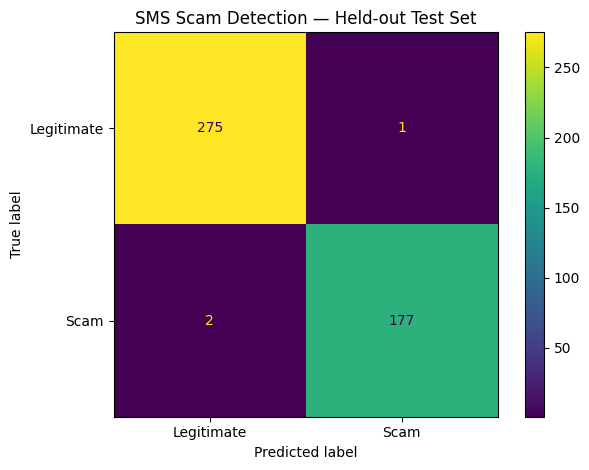

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on the held-out test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("=== TEST SET RESULTS ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1 score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Legitimate (ham)", "Scam (spam)"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Legitimate", "Scam"],
    values_format="d"
)
plt.title("SMS Scam Detection — Held-out Test Set")
plt.tight_layout()
plt.show()

In [24]:
import joblib

joblib.dump(model, "sms_scam_baseline.joblib")
print("Saved: sms_scam_baseline.joblib")

Saved: sms_scam_baseline.joblib


In [25]:
# Test on new, unseen example messages

test_messages = [
    # Scam examples
    "A caller claiming to be from CBI threatened to arrest me unless I transferred money.",
    "Your bank account will be blocked in five minutes. Tell me the OTP now.",
    "Someone said my Aadhaar was linked to a crime and ordered me to stay on a video call.",

    # Legitimate examples
    "My bank asked me to check my debit card application in its official app.",
    "The police issued a public warning about digital arrest scams. Never transfer money to callers.",
    "My college called to confirm tomorrow's examination timetable."
]

predictions = model.predict(test_messages)
probabilities = model.predict_proba(test_messages)[:, 1]

for text, pred, prob in zip(
    test_messages, predictions, probabilities
):
    label = "SCAM" if pred == 1 else "LEGITIMATE"
    print(f"\nPrediction: {label}")
    print(f"Model scam score: {prob:.1%}")
    print(f"Message: {text}")


Prediction: LEGITIMATE
Model scam score: 35.6%
Message: A caller claiming to be from CBI threatened to arrest me unless I transferred money.

Prediction: SCAM
Model scam score: 60.8%
Message: Your bank account will be blocked in five minutes. Tell me the OTP now.

Prediction: LEGITIMATE
Model scam score: 42.4%
Message: Someone said my Aadhaar was linked to a crime and ordered me to stay on a video call.

Prediction: LEGITIMATE
Model scam score: 40.5%
Message: My bank asked me to check my debit card application in its official app.

Prediction: LEGITIMATE
Model scam score: 22.4%
Message: The police issued a public warning about digital arrest scams. Never transfer money to callers.

Prediction: LEGITIMATE
Model scam score: 21.7%
Message: My college called to confirm tomorrow's examination timetable.


In [26]:
# Cell 14: Inspect ICFD-31k schema and split sizes

print("ICFD-31k splits:")
for split_name, data in icfd.items():
    print(f"{split_name}: {len(data):,} rows")

print("\nTraining columns:")
print(icfd["train"].column_names)

print("\nTraining feature definitions:")
print(icfd["train"].features)

print("\nSample records:")
for i in range(min(3, len(icfd["train"]))):
    print(f"\nRecord {i + 1}:")
    print(icfd["train"][i])

ICFD-31k splits:
train: 712,316 rows
validation: 173,813 rows
test: 179,827 rows

Training columns:
['dataset', 'release_version', 'split', 'domain', 'source_batch', 'source_file_stem', 'chunk_file', 'conversation_uid', 'session_id', 'chunk_timestamp', 'final_verdict', 'slow_thinking_rationale', 'cumulative_text', 'cumulative_transcript_json', 'cumulative_audio_analysis_json', 'scenario_info_json', 'scenario_id', 'case_type', 'combination_key', 'multiplier_round', 'generated_at']

Training feature definitions:
{'dataset': Value('string'), 'release_version': Value('string'), 'split': Value('string'), 'domain': Value('string'), 'source_batch': Value('string'), 'source_file_stem': Value('string'), 'chunk_file': Value('string'), 'conversation_uid': Value('string'), 'session_id': Value('int64'), 'chunk_timestamp': Value('int64'), 'final_verdict': Value('string'), 'slow_thinking_rationale': Value('string'), 'cumulative_text': Value('string'), 'cumulative_transcript_json': Value('string'), 'c

In [27]:
# Print every ICFD field without truncating column names

train_data = icfd["train"]

print("Total columns:", len(train_data.column_names))

for col in train_data.column_names:
    print(f"\nColumn: {col}")
    print("Feature type:", train_data.features[col])

print("\n========== FULL SAMPLE RECORD ==========")

sample = train_data[0]

for key, value in sample.items():
    print(f"\n{key}:")
    print(str(value)[:1500])

print("\n========== LABEL CANDIDATES ==========")

for col in train_data.column_names:
    name = col.lower()
    if any(word in name for word in [
        "label", "target", "class", "fraud", "scam",
        "text", "transcript", "conversation"
    ]):
        print(f"\n{col}")
        print(train_data[col][:3])

Total columns: 21

Column: dataset
Feature type: Value('string')

Column: release_version
Feature type: Value('string')

Column: split
Feature type: Value('string')

Column: domain
Feature type: Value('string')

Column: source_batch
Feature type: Value('string')

Column: source_file_stem
Feature type: Value('string')

Column: chunk_file
Feature type: Value('string')

Column: conversation_uid
Feature type: Value('string')

Column: session_id
Feature type: Value('int64')

Column: chunk_timestamp
Feature type: Value('int64')

Column: final_verdict
Feature type: Value('string')

Column: slow_thinking_rationale
Feature type: Value('string')

Column: cumulative_text
Feature type: Value('string')

Column: cumulative_transcript_json
Feature type: Value('string')

Column: cumulative_audio_analysis_json
Feature type: Value('string')

Column: scenario_info_json
Feature type: Value('string')

Column: scenario_id
Feature type: Value('int64')

Column: case_type
Feature type: Value('string')

Column:

In [28]:
from collections import Counter

train_data = icfd["train"]

# Inspect likely label and transcript fields
for col in train_data.column_names:
    name = col.lower()
    if any(k in name for k in [
        "case_type", "label", "target", "cumulative_text",
        "transcript", "scenario_info", "conversation_uid"
    ]):
        print(f"\n--- {col} ---")
        print("Feature:", train_data.features[col])

        if col == "case_type":
            print("Values:", Counter(train_data[col]))
        else:
            print("Example:", str(train_data[0][col])[:1000])


--- conversation_uid ---
Feature: Value('string')
Example: batch_2025-10-11_21-42-13/SCENARIO_10_Clear_Fraud_0901_r1

--- cumulative_text ---
Feature: Value('string')
Example: Agent: Hello, sir, this is Agent Kumar from Punjab National Bank. We are updating our records and I need to verify some information with you, ji.
Customer: Achha, yes, of course. What do you need to know, sir?
Agent: Can you please tell me your mother's maiden name, sir? This is just for our security purposes.
Customer: Thik hai, my mother's maiden name is Patel.
Agent: Great, thank you, sir. And can you also tell me your place of birth?
Customer: I was born in Mumbai, sir.
Agent: Okay, and what was the name of your first school, sir?
Customer: My first school was St. Mary's High School, sir.
Agent: Alright, sir, that's all the information I need for now. We will update our records accordingly.
Customer: Okay, thank you, sir. Is there anything else I need to do?

--- cumulative_transcript_json ---
Feature: Value

In [29]:
from collections import Counter

for split_name, data in icfd.items():
    print(f"\n=== {split_name.upper()} ===")
    counts = Counter(data["case_type"])
    for label, count in counts.most_common():
        print(f"{label}: {count:,}")


=== TRAIN ===
Clear Normal: 306,171
Ambiguous but Ultimately Normal: 176,956
Subtle Fraud: 152,615
Clear Fraud: 76,574

=== VALIDATION ===
Clear Fraud: 136,540
Subtle Fraud: 37,273

=== TEST ===
Clear Fraud: 179,827


In [30]:
data = icfd["train"]

print("All case types:")
print(sorted(set(data["case_type"])))

print("\nScenario metadata examples:")
for i in range(5):
    print(f"\nCase type: {data[i]['case_type']}")
    print("Transcript:", data[i]["cumulative_text"][:700])

All case types:
['Ambiguous but Ultimately Normal', 'Clear Fraud', 'Clear Normal', 'Subtle Fraud']

Scenario metadata examples:

Case type: Clear Fraud
Transcript: Agent: Hello, sir, this is Agent Kumar from Punjab National Bank. We are updating our records and I need to verify some information with you, ji.
Customer: Achha, yes, of course. What do you need to know, sir?
Agent: Can you please tell me your mother's maiden name, sir? This is just for our security purposes.
Customer: Thik hai, my mother's maiden name is Patel.
Agent: Great, thank you, sir. And can you also tell me your place of birth?
Customer: I was born in Mumbai, sir.
Agent: Okay, and what was the name of your first school, sir?
Customer: My first school was St. Mary's High School, sir.
Agent: Alright, sir, that's all the information I need for now. We will update our records according

Case type: Clear Fraud
Transcript: Agent: Hello, sir, this is Agent Kumar from Punjab National Bank. We are updating our records and I

In [31]:
from collections import Counter
import hashlib

print("=== LABEL DISTRIBUTION ===")
for split_name, data in icfd.items():
    print(f"\n{split_name}:")
    print(Counter(data["case_type"]))

# Sample repeated transcript check
print("\n=== DUPLICATE CHECK (up to 10,000 rows per split) ===")
for split_name, data in icfd.items():
    n = min(10_000, len(data))
    rows = data.select(range(n))
    texts = [str(x).strip() for x in rows["cumulative_text"]]
    ids = rows["conversation_uid"]

    print(f"\n{split_name}:")
    print("Rows sampled:", n)
    print("Unique conversation IDs:", len(set(ids)))
    print("Unique transcript texts:", len(set(texts)))
    print("Repeated transcript rows:", n - len(set(texts)))

# Check conversation ID overlap across official splits
print("\n=== CONVERSATION ID OVERLAP ===")
split_ids = {
    name: set(data.select(range(min(100_000, len(data))))["conversation_uid"])
    for name, data in icfd.items()
}
names = list(split_ids)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        overlap = split_ids[names[i]] & split_ids[names[j]]
        print(f"{names[i]} vs {names[j]}: {len(overlap)} IDs overlap in inspected prefixes")

=== LABEL DISTRIBUTION ===

train:
Counter({'Clear Normal': 306171, 'Ambiguous but Ultimately Normal': 176956, 'Subtle Fraud': 152615, 'Clear Fraud': 76574})

validation:
Counter({'Clear Fraud': 136540, 'Subtle Fraud': 37273})

test:
Counter({'Clear Fraud': 179827})

=== DUPLICATE CHECK (up to 10,000 rows per split) ===

train:
Rows sampled: 10000
Unique conversation IDs: 248
Unique transcript texts: 3833
Repeated transcript rows: 6167

validation:
Rows sampled: 10000
Unique conversation IDs: 245
Unique transcript texts: 3836
Repeated transcript rows: 6164

test:
Rows sampled: 10000
Unique conversation IDs: 204
Unique transcript texts: 3764
Repeated transcript rows: 6236

=== CONVERSATION ID OVERLAP ===
train vs validation: 0 IDs overlap in inspected prefixes
train vs test: 0 IDs overlap in inspected prefixes
validation vs test: 0 IDs overlap in inspected prefixes


In [32]:
import pandas as pd

# Inspect a sample from each official split
frames = []

for split_name, data in icfd.items():
    n = min(20000, len(data))
    sample = data.select(range(n)).to_pandas()

    frames.append(pd.DataFrame({
        "split": split_name,
        "text": sample["cumulative_text"].fillna("").astype(str).str.strip(),
        "case_type": sample["case_type"].astype(str),
        "conversation_uid": sample["conversation_uid"].astype(str)
    }))

audit_df = pd.concat(frames, ignore_index=True)
audit_df = audit_df[audit_df["text"].str.len() > 0]

# Count labels assigned to each exact transcript
text_groups = audit_df.groupby("text").agg(
    rows=("case_type", "size"),
    label_count=("case_type", "nunique"),
    labels=("case_type", lambda x: sorted(set(x))),
    splits=("split", lambda x: sorted(set(x)))
).reset_index()

print("Sampled rows:", len(audit_df))
print("Unique exact transcripts:", len(text_groups))
print("Transcripts with conflicting labels:",
      int((text_groups["label_count"] > 1).sum()))

print("\nMost repeated transcripts:")
display(
    text_groups.sort_values("rows", ascending=False)
    .head(10)[["rows", "label_count", "labels", "splits", "text"]]
)

Sampled rows: 60000
Unique exact transcripts: 23419
Transcripts with conflicting labels: 0

Most repeated transcripts:


,rows,label_count,labels,splits,text
20070,100,1,[Clear Normal],[train],"Agent: Namaste Zubin ji, this is Rohan from La..."
19132,96,1,[Clear Normal],[train],"Agent: Namaste Tanusree ji, I hope you're doin..."
21493,92,1,[Clear Normal],[train],"Agent: Namaste, Subramanian Kumar ji, this is ..."
22683,92,1,[Clear Fraud],[validation],"Agent: Namaste, sir. Kaise ho aap? My name is ..."
1454,91,1,[Clear Normal],[train],"Agent: Hello Sir, this is a marketing call fro..."
17928,90,1,[Clear Fraud],[validation],"Agent: Namaste Santanu ji, mera naam Rohan hai..."
20515,82,1,[Clear Fraud],[train],"Agent: Namaste, Asha ji. Kaise ho aap? How can..."
19449,81,1,[Clear Fraud],[test],"Agent: Namaste Ujjwal ji, I hope you're doing ..."
12020,78,1,[Clear Normal],[train],"Agent: Namaste Bharati ji, this is Ramesh from..."
10531,77,1,[Clear Normal],[train],"Agent: Hello, sir. This is a call from Jio Pay..."


In [33]:
import pandas as pd

# Use ONLY the official training split for initial model development
train_df = icfd["train"].to_pandas()[
    ["cumulative_text", "case_type", "conversation_uid"]
].copy()

train_df["text"] = train_df["cumulative_text"].fillna("").astype(str).str.strip()
train_df["case_type"] = train_df["case_type"].astype(str)

# Map the four documented categories to binary labels
label_map = {
    "Clear Fraud": 1,
    "Subtle Fraud": 1,
    "Clear Normal": 0,
    "Ambiguous but Ultimately Normal": 0,
}

train_df["label"] = train_df["case_type"].map(label_map)

# Remove empty text and unknown categories
train_df = train_df[
    train_df["text"].ne("") & train_df["label"].notna()
].copy()

# Check if identical texts have conflicting labels
conflicts = train_df.groupby("text")["label"].nunique()
conflict_texts = conflicts[conflicts > 1].index

print("Training rows before deduplication:", len(train_df))
print("Conflicting exact transcripts:", len(conflict_texts))

# Exclude conflicting texts, then deduplicate
train_df = train_df[~train_df["text"].isin(conflict_texts)]
train_df = train_df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("\nRows after cleaning:", len(train_df))
print("Label distribution:")
print(train_df["label"].value_counts())
print("\nUnique conversation IDs:", train_df["conversation_uid"].nunique())

Training rows before deduplication: 712316
Conflicting exact transcripts: 154

Rows after cleaning: 253761
Label distribution:
label
0    174100
1     79661
Name: count, dtype: int64

Unique conversation IDs: 20996


In [34]:
from sklearn.model_selection import GroupShuffleSplit

# Keep one group per conversation ID
groups = train_df["conversation_uid"].astype(str)
X = train_df["text"]
y = train_df["label"].astype(int)

# 80% training, 20% validation, grouped by conversation
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_val = X.iloc[val_idx]
y_val = y.iloc[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print(
    "\nConversation overlap:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[val_idx]))
)

Training rows: 203136
Validation rows: 50625

Training labels:
label
0    139620
1     63516
Name: count, dtype: int64

Validation labels:
label
0    34480
1    16145
Name: count, dtype: int64

Conversation overlap: 0


In [35]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import joblib
import time

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents=None,
        ngram_range=(1, 2),
        min_df=2,
        max_features=150_000,
        sublinear_tf=True,
        dtype="float32"
    )),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ))
])

start = time.time()

model.fit(X_train, y_train)

print(f"Training completed in {(time.time() - start) / 60:.2f} minutes")
print("Model trained on:", len(X_train), "transcripts")
print("Vocabulary size:", len(model.named_steps["tfidf"].vocabulary_))

joblib.dump(model, "digital_scam_transcript_model.joblib")
print("Saved digital_scam_transcript_model.joblib")

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Training completed in 0.94 minutes
Model trained on: 203136 transcripts
Vocabulary size: 150000
Saved digital_scam_transcript_model.joblib


              precision    recall  f1-score   support

  Legitimate     0.9809    0.9824    0.9817     34480
       Fraud     0.9623    0.9592    0.9608     16145

    accuracy                         0.9750     50625
   macro avg     0.9716    0.9708    0.9712     50625
weighted avg     0.9750    0.9750    0.9750     50625

ROC-AUC: 0.9972
Confusion matrix:
[[33874   606]
 [  658 15487]]


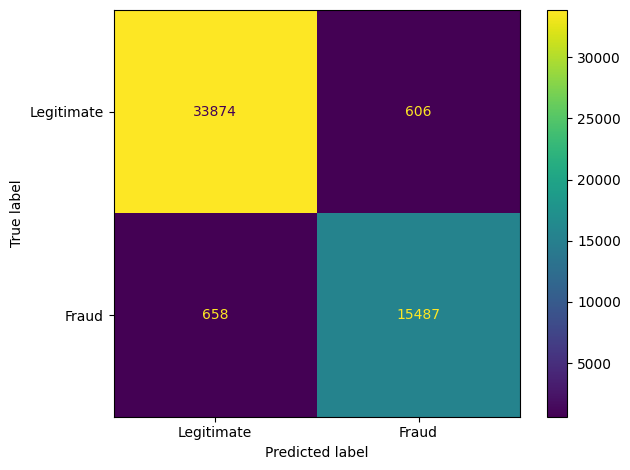

In [36]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

val_pred = model.predict(X_val)
val_prob = model.predict_proba(X_val)[:, 1]

print(classification_report(
    y_val,
    val_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_val, val_prob), 4))

print("Confusion matrix:")
print(confusion_matrix(y_val, val_pred, labels=[0, 1]))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    labels=[0, 1],
    display_labels=["Legitimate", "Fraud"],
    values_format="d"
)
plt.tight_layout()
plt.show()

In [37]:
test_cases = [
    (
        "Digital arrest scam",
        "A caller claimed to be from the CBI, threatened to arrest me, "
        "ordered me to stay on a video call, and demanded money."
    ),
    (
        "OTP scam",
        "Someone claiming to be from my bank demanded my OTP immediately "
        "and threatened to block my account."
    ),
    (
        "Legitimate bank call",
        "My bank asked me to check my debit card application using its "
        "official mobile banking app. They did not ask for money or an OTP."
    ),
    (
        "Public awareness message",
        "Police warned citizens that scammers may impersonate CBI officers "
        "and demand money. Citizens should report suspicious calls."
    ),
    (
        "Subtle suspicious call",
        "Someone called about a problem with my identity documents and "
        "told me to keep it secret from my family and cooperate to avoid "
        "legal action."
    )
]

for name, text in test_cases:
    scam_probability = model.predict_proba([text])[0][1]
    prediction = "FRAUD" if scam_probability >= 0.5 else "LEGITIMATE"

    print(f"\n{name}")
    print(f"Prediction: {prediction}")
    print(f"Model fraud score: {scam_probability:.1%}")


Digital arrest scam
Prediction: LEGITIMATE
Model fraud score: 35.3%

OTP scam
Prediction: LEGITIMATE
Model fraud score: 46.5%

Legitimate bank call
Prediction: LEGITIMATE
Model fraud score: 34.0%

Public awareness message
Prediction: LEGITIMATE
Model fraud score: 42.5%

Subtle suspicious call
Prediction: LEGITIMATE
Model fraud score: 16.4%


In [38]:
import pandas as pd
import numpy as np

tfidf = model.named_steps["tfidf"]
clf = model.named_steps["classifier"]

feature_names = np.array(tfidf.get_feature_names_out())
weights = clf.coef_[0]

fraud_idx = np.argsort(weights)[-30:][::-1]
normal_idx = np.argsort(weights)[:30]

print("=== FEATURES MOST ASSOCIATED WITH FRAUD ===")
display(pd.DataFrame({
    "feature": feature_names[fraud_idx],
    "weight": weights[fraud_idx]
}))

print("\n=== FEATURES MOST ASSOCIATED WITH LEGITIMATE ===")
display(pd.DataFrame({
    "feature": feature_names[normal_idx],
    "weight": weights[normal_idx]
}))

=== FEATURES MOST ASSOCIATED WITH FRAUD ===


,feature,weight
0,refund,11.715579
1,sim,8.150016
2,account,7.568060
3,new sim,7.553502
4,sim card,7.121561
5,fee,7.048143
6,court,6.938586
7,tower,6.655736
8,health,6.489040
9,prize,6.429182



=== FEATURES MOST ASSOCIATED WITH LEGITIMATE ===


,feature,weight
0,delivery,-7.083459
1,plan,-6.260664
2,our official,-5.855869
3,bank hr,-5.485412
4,credit card,-5.342730
5,official,-5.277849
6,email,-5.164200
7,feedback,-5.075053
8,claim,-4.950287
9,annual,-4.877094


In [39]:
import pandas as pd
import numpy as np

tfidf = model.named_steps["tfidf"]
clf = model.named_steps["classifier"]

features = np.array(tfidf.get_feature_names_out())
weights = clf.coef_[0]

# Highest positive weights: associated with fraud
fraud_idx = np.argsort(weights)[-30:][::-1]

print("=== TOP 30 FRAUD-ASSOCIATED FEATURES ===")
display(pd.DataFrame({
    "feature": features[fraud_idx],
    "weight": weights[fraud_idx]
}).reset_index(drop=True))

=== TOP 30 FRAUD-ASSOCIATED FEATURES ===


,feature,weight
0,refund,11.715579
1,sim,8.150016
2,account,7.568060
3,new sim,7.553502
4,sim card,7.121561
5,fee,7.048143
6,court,6.938586
7,tower,6.655736
8,health,6.489040
9,prize,6.429182


In [40]:
import pandas as pd

# Inspect validation errors
error_df = pd.DataFrame({
    "text": X_val.reset_index(drop=True),
    "actual": y_val.reset_index(drop=True),
    "predicted": val_pred,
    "fraud_score": val_prob
})

errors = error_df[error_df["actual"] != error_df["predicted"]].copy()

errors["actual_label"] = errors["actual"].map({
    0: "LEGITIMATE",
    1: "FRAUD"
})

errors["predicted_label"] = errors["predicted"].map({
    0: "LEGITIMATE",
    1: "FRAUD"
})

print("Total validation errors:", len(errors))
print("\nMissed fraud examples:")
display(
    errors[errors["actual"] == 1][
        ["actual_label", "predicted_label", "fraud_score", "text"]
    ].head(10)
)

print("\nLegitimate examples incorrectly flagged:")
display(
    errors[errors["actual"] == 0][
        ["actual_label", "predicted_label", "fraud_score", "text"]
    ].head(10)
)

Total validation errors: 1264

Missed fraud examples:


,actual_label,predicted_label,fraud_score,text
56,FRAUD,LEGITIMATE,0.312252,"Agent: Namaste Raghuveer ji, main Utkarsh Smal..."
62,FRAUD,LEGITIMATE,0.436226,"Agent: Namaste Raghuveer ji, main Utkarsh Smal..."
71,FRAUD,LEGITIMATE,0.478642,"Agent: Hello Sir, ji, this is Rohan from Kotak..."
124,FRAUD,LEGITIMATE,0.266361,"Agent: Namaste Sir, this is Ramesh from Fino P..."
171,FRAUD,LEGITIMATE,0.466416,"Agent: Namaste Ayesha Begum ji, main Tamilnad ..."
172,FRAUD,LEGITIMATE,0.483600,"Agent: Namaste Ayesha Begum ji, main Tamilnad ..."
173,FRAUD,LEGITIMATE,0.478889,"Agent: Namaste Ayesha Begum ji, main Tamilnad ..."
174,FRAUD,LEGITIMATE,0.470877,"Agent: Namaste Ayesha Begum ji, main Tamilnad ..."
175,FRAUD,LEGITIMATE,0.465257,"Agent: Namaste Ayesha Begum ji, main Tamilnad ..."
176,FRAUD,LEGITIMATE,0.458810,"Agent: Namaste Ayesha Begum ji, main Tamilnad ..."



Legitimate examples incorrectly flagged:


,actual_label,predicted_label,fraud_score,text
473,LEGITIMATE,FRAUD,0.584173,"Agent: Namaste Hari ji, kaise ho aap?\nCustome..."
482,LEGITIMATE,FRAUD,0.731000,"Agent: Namaste Hari ji, kaise ho aap?"
489,LEGITIMATE,FRAUD,0.532427,"Agent: Namaste Chandran ji, this is Rohan from..."
790,LEGITIMATE,FRAUD,0.564467,"Agent: Namaste Gauri ji, kaise hain aap? This ..."
861,LEGITIMATE,FRAUD,0.735778,"Agent: Namaste, Mr. Patel. Sir, how are you to..."
872,LEGITIMATE,FRAUD,0.793080,"Agent: Namaste, Mr. Patel. Sir, how are you to..."
1591,LEGITIMATE,FRAUD,0.727049,"Agent: Namaste Ahmed ji, kaise ho aap? Is this..."
1662,LEGITIMATE,FRAUD,0.519607,"Agent: Hello, namaste Hemwati Devi ji! This is..."
1718,LEGITIMATE,FRAUD,0.571455,"Agent: Hello, namaste Hemwati Devi ji! This is..."
1748,LEGITIMATE,FRAUD,0.746108,"Agent: Namaste Natarajan ji, this is Rohan fro..."


In [41]:
import pandas as pd

# Inspect repeated validation errors
fraud_errors = errors[errors["actual"] == 1].copy()
normal_errors = errors[errors["actual"] == 0].copy()

print("=== MISSED FRAUD: REPEATED TEXT CHECK ===")
fraud_errors["text_length"] = fraud_errors["text"].str.len()

display(
    fraud_errors[
        ["text_length", "fraud_score", "text"]
    ].sort_values("text_length").head(15)
)

print("\n=== FALSE POSITIVES: EMPTY/SHORT TEXT CHECK ===")
normal_errors["text_length"] = normal_errors["text"].str.len()

display(
    normal_errors[
        ["text_length", "fraud_score", "text"]
    ].sort_values("text_length").head(15)
)

print("\nValidation rows with empty or very short text:")
print("Empty:", int((X_val.str.strip().str.len() == 0).sum()))
print("Under 30 characters:", int((X_val.str.strip().str.len() < 30).sum()))

=== MISSED FRAUD: REPEATED TEXT CHECK ===


,text_length,fraud_score,text
34818,36,0.439083,"Customer: Hello? Hello, who is this?"
28181,37,0.073313,"Agent: Hello, is this Savitha Balaji?"
37270,38,0.210062,"Agent: Hello, sir. Is this Irfan Lone?"
23635,40,0.293359,"Agent: Hello, is this Mr. Jhilmil Sarma?"
31883,41,0.216698,"Agent: Hello, is this Mr. Prakash Rajput?"
28404,41,0.121553,"Agent: Hello, is this Ms. Savitha Balaji?"
45793,41,0.400910,"Agent: Hello, is this Mr. Vishal Agarwal?"
37285,42,0.244336,"Agent: Hello, sir. Is this Mr. Ram Prasad?"
6548,43,0.479737,"Agent: Hello, is this Bhavya Srinivas? Sir?"
41114,43,0.401712,"Agent: Hello, is this Ms. Elizabeth George?"



=== FALSE POSITIVES: EMPTY/SHORT TEXT CHECK ===


,text_length,fraud_score,text
34117,31,0.576368,"Customer: Hey, ji, how are you?"
15523,32,0.729180,"Agent: Hello, sir. Kaise ho aap?"
34360,33,0.580981,"Agent: Hello, is this Onkar Kaur?"
48044,34,0.665403,"Agent: Hello, is this Usha Kumari?"
20058,35,0.508967,"Agent: Hello, is this Pallavi Nene?"
29581,35,0.534872,"Agent: Hello, is this Harleen Kaur?"
482,37,0.731000,"Agent: Namaste Hari ji, kaise ho aap?"
24011,38,0.548547,"Agent: Hello, is this Harleen Kaur ji?"
4767,38,0.639835,"Agent: Namaste Gopal ji, kaise ho aap?"
15954,39,0.522555,"Agent: Hello, is this Ayesha Begum, ji?"



Validation rows with empty or very short text:
Empty: 0
Under 30 characters: 0


In [42]:
import pandas as pd

# Analyze conversation structure in the cleaned training data
conversation_audit = (
    train_df.groupby("conversation_uid")
    .agg(
        rows=("text", "size"),
        unique_texts=("text", "nunique"),
        labels=("label", "nunique"),
        min_text_length=("text", lambda x: x.str.len().min()),
        max_text_length=("text", lambda x: x.str.len().max())
    )
    .reset_index()
)

print("Unique conversations:", len(conversation_audit))
print("Conversations with multiple rows:",
      int((conversation_audit["rows"] > 1).sum()))
print("Conversations with conflicting labels:",
      int((conversation_audit["labels"] > 1).sum()))

print("\nConversation row-count distribution:")
print(conversation_audit["rows"].describe(percentiles=[.5, .75, .9, .95, .99]))

print("\nLargest conversations:")
display(
    conversation_audit.sort_values("rows", ascending=False).head(10)
)

Unique conversations: 20996
Conversations with multiple rows: 20996
Conversations with conflicting labels: 0

Conversation row-count distribution:
count    20996.000000
mean        12.086159
std          6.287746
min          2.000000
50%         11.000000
75%         13.000000
90%         17.000000
95%         22.000000
99%         42.000000
max         81.000000
Name: rows, dtype: float64

Largest conversations:


,conversation_uid,rows,unique_texts,labels,min_text_length,max_text_length
411,batch_2025-10-11_21-42-13/SCENARIO_14_Clear_No...,81,81,1,116,3339
877,batch_2025-10-11_21-42-13/SCENARIO_18_Clear_No...,71,71,1,100,2651
498,batch_2025-10-11_21-42-13/SCENARIO_14_Clear_No...,70,70,1,86,3351
1462,batch_2025-10-11_21-42-13/SCENARIO_23_Ambiguou...,70,70,1,97,3062
1307,batch_2025-10-11_21-42-13/SCENARIO_22_Ambiguou...,70,70,1,113,2696
662,batch_2025-10-11_21-42-13/SCENARIO_16_Clear_No...,69,69,1,85,2800
719,batch_2025-10-11_21-42-13/SCENARIO_17_Clear_No...,69,69,1,85,5492
1268,batch_2025-10-11_21-42-13/SCENARIO_21_Ambiguou...,69,69,1,137,3061
419,batch_2025-10-11_21-42-13/SCENARIO_14_Clear_No...,69,69,1,111,3353
1019,batch_2025-10-11_21-42-13/SCENARIO_1_Clear_Fra...,69,69,1,86,4753


In [43]:
import pandas as pd

# Use the cleaned training data only
conversation_df = (
    train_df.sort_values("text", key=lambda s: s.str.len())
    .groupby("conversation_uid", as_index=False)
    .tail(1)
    .reset_index(drop=True)
)

# Keep one row per conversation
conversation_df = conversation_df[
    ["conversation_uid", "text", "label", "case_type"]
].copy()

print("Original fragment rows:", len(train_df))
print("Unique conversation records:", len(conversation_df))
print("\nClass distribution:")
print(conversation_df["label"].value_counts())

print("\nTranscript length statistics:")
print(conversation_df["text"].str.len().describe())

print("\nDuplicate complete texts:",
      conversation_df["text"].duplicated().sum())

display(conversation_df.head(5))

Original fragment rows: 253761
Unique conversation records: 20996

Class distribution:
label
0    14997
1     5999
Name: count, dtype: int64

Transcript length statistics:
count    20996.000000
mean      1278.124119
std        468.627125
min        169.000000
25%        955.000000
50%       1211.000000
75%       1516.000000
max       5492.000000
Name: text, dtype: float64

Duplicate complete texts: 0


,conversation_uid,text,label,case_type
0,batch_2025-10-13_01-36-50/SCENARIO_25_Ambiguou...,"Customer: Hello?\nAgent: Mom? I'm in trouble, ...",0,Ambiguous but Ultimately Normal
1,batch_2025-10-13_01-36-50/SCENARIO_25_Ambiguou...,"Customer: Hello? Hello, who is this? Sir?\nAge...",0,Ambiguous but Ultimately Normal
2,batch_2025-10-11_21-42-13/SCENARIO_11_Clear_No...,"Agent: Hello Sir, this is IndusInd Bank. I am ...",0,Clear Normal
3,batch_2025-10-13_02-53-33/SCENARIO_18_Clear_No...,"Agent: Hello, this is an automated call from I...",0,Clear Normal
4,batch_2025-10-13_02-53-33/SCENARIO_18_Clear_No...,"Agent: Hello, this is an automated call from I...",0,Clear Normal


In [44]:
import re
from sklearn.model_selection import GroupShuffleSplit

# Extract the scenario ID from conversation_uid
conversation_df["scenario_group"] = (
    conversation_df["conversation_uid"]
    .str.extract(r"(SCENARIO_\d+)", expand=False)
)

print("Missing scenario groups:",
      conversation_df["scenario_group"].isna().sum())
print("Unique scenario groups:",
      conversation_df["scenario_group"].nunique())

# Stop if the expected scenario format isn't present
assert conversation_df["scenario_group"].notna().all(), (
    "Some IDs do not contain SCENARIO_<number>. Inspect those IDs first."
)

X = conversation_df["text"].astype(str)
y = conversation_df["label"].astype(int)
groups = conversation_df["scenario_group"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]
X_val = X.iloc[val_idx]
y_val = y.iloc[val_idx]

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_val))
print("\nTraining label counts:")
print(y_train.value_counts())
print("\nValidation label counts:")
print(y_val.value_counts())
print("\nScenario overlap:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])))

Missing scenario groups: 0
Unique scenario groups: 21

Training records: 15996
Validation records: 5000

Training label counts:
label
0    12997
1     2999
Name: count, dtype: int64

Validation label counts:
label
1    3000
0    2000
Name: count, dtype: int64

Scenario overlap: 0


In [45]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# Train using the scenario-separated datasets from your previous cell
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=150_000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Training model...")
model.fit(X_train, y_train)

# Evaluate on scenarios not used during training
y_pred = model.predict(X_val)
y_prob = model.predict_proba(X_val)[:, 1]

print("\nAccuracy:", round(accuracy_score(y_val, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_prob), 4))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Scam"],
    digits=4
))

print("Confusion matrix:")
print(confusion_matrix(y_val, y_pred, labels=[0, 1]))

Training model...

Accuracy: 0.7562
ROC-AUC: 0.9375

Classification report:
              precision    recall  f1-score   support

  Legitimate     0.6288    0.9530    0.7577      2000
        Scam     0.9523    0.6250    0.7547      3000

    accuracy                         0.7562      5000
   macro avg     0.7905    0.7890    0.7562      5000
weighted avg     0.8229    0.7562    0.7559      5000

Confusion matrix:
[[1906   94]
 [1125 1875]]


In [46]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Scam precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Scam recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "Scam F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False alarms": int(
            ((predictions == 1) & (y_val == 0)).sum()
        ),
        "Missed scams": int(
            ((predictions == 0) & (y_val == 1)).sum()
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(3).to_string(index=False))

 Threshold  Scam precision  Scam recall  Scam F1  False alarms  Missed scams
      0.20           0.841        0.970    0.901           550            90
      0.25           0.872        0.931    0.901           410           206
      0.30           0.894        0.881    0.888           314           356
      0.35           0.908        0.822    0.863           249           534
      0.40           0.927        0.763    0.837           180           712
      0.45           0.944        0.691    0.798           123           926
      0.50           0.952        0.625    0.755            94          1125
      0.55           0.958        0.551    0.699            73          1348
      0.60           0.962        0.477    0.638            57          1569


In [47]:
import joblib
import os

MODEL_DIR = "/content/digital_safety_model"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "scam_detector.joblib")

model_package = {
    "model": model,
    "threshold": 0.20,
    "label_meanings": {
        0: "Legitimate",
        1: "Potential scam"
    },
    "model_type": "TF-IDF + Logistic Regression",
    "training_unit": "Complete conversation transcripts"
}

joblib.dump(model_package, MODEL_PATH)

print("Model saved to:", MODEL_PATH)
print("Decision threshold:", model_package["threshold"])
print("Saved model size (MB):",
      round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2))

Model saved to: /content/digital_safety_model/scam_detector.joblib
Decision threshold: 0.2
Saved model size (MB): 4.98


In [48]:
loaded_package = joblib.load(MODEL_PATH)
loaded_model = loaded_package["model"]
threshold = loaded_package["threshold"]

test_text = """
Caller: Your Aadhaar number is linked to a criminal case.
You must stay on a video call and transfer money for verification.
"""

scam_probability = loaded_model.predict_proba([test_text])[0, 1]

print(f"Potential-scam score: {scam_probability:.1%}")
print("Prediction:",
      "Potential scam — review carefully"
      if scam_probability >= threshold
      else "Not flagged by the current threshold")

Potential-scam score: 26.0%
Prediction: Potential scam — review carefully


In [49]:
!pip -q install gradio

In [50]:
import joblib
import time

print("Loading saved model...", flush=True)

package = joblib.load(
    "/content/digital_safety_model/scam_detector.joblib"
)

detector = package["model"]
threshold = package["threshold"]

print("Model loaded. Testing one transcript...", flush=True)

sample = (
    "Caller: I am a police officer. Your Aadhaar is linked "
    "to a criminal case. Transfer money immediately or you "
    "will be arrested."
)

start = time.time()
score = detector.predict_proba([sample])[0, 1]

print("Prediction completed in", round(time.time() - start, 2), "seconds")
print("Potential-scam score:", f"{score:.1%}")
print("Result:", "Potential scam" if score >= threshold else "Not flagged")

Loading saved model...
Model loaded. Testing one transcript...
Prediction completed in 0.0 seconds
Potential-scam score: 25.7%
Result: Potential scam


In [54]:
import pandas as pd
from IPython.display import display

# Define the threshold from the loaded model package or set to 0.30
THRESHOLD = globals().get('threshold', 0.30)

test_cases = [
    ("Digital arrest scam", 1,
     "Police officer calling about your Aadhaar. You are involved "
     "in a criminal case. Transfer money for verification or be arrested."),
    ("OTP theft", 1,
     "I am from bank support. Tell me the OTP you received to unblock "
     "your account or it will be frozen."),
    ("Fake parcel threat", 1,
     "Your parcel contains illegal items. Transfer money now to clear "
     "your name or you will be arrested."),
    ("Legitimate bank call", 0,
     "I am calling from your bank about your service request. "
     "Never share your OTP, PIN or password. Verify using the official number."),
    ("Legitimate delivery", 0,
     "Your parcel is out for delivery today. Check tracking in the "
     "official delivery app. No payment is required on this call."),
    ("Suspicious KYC request", 1,
     "Your KYC expires today. Install this remote access application "
     "and tell me the code on your screen."),
    ("Hinglish digital arrest", 1,
     "Main cyber crime department se bol raha hoon. Aapke Aadhaar par "
     "case hai. Paise transfer kijiye warna arrest hoga."),
    ("Hinglish legitimate bank", 0,
     "Namaste sir, main bank customer service se bol raha hoon. "
     "Aapki service request ka status batana tha. OTP ya PIN mat batayiye."),
    ("Ambiguous opening", 0,
     "Hello sir, main aapko aapke account ke baare mein call kar raha hoon. "
     "Kya abhi baat kar sakte hain?"),
    ("Prize scam", 1,
     "Congratulations, you won a cash prize. Pay a processing fee "
     "and send your bank details to release the money.")
]

rows = []

for name, expected, text in test_cases:
    score = float(detector.predict_proba([text])[0, 1])
    predicted = int(score >= THRESHOLD)

    rows.append({
        "Test case": name,
        "Expected": "Scam" if expected else "Legitimate",
        "Predicted": "Scam" if predicted else "Legitimate",
        "Scam score": f"{score:.1%}",
        "Result": "PASS" if predicted == expected else "FAIL"
    })

results_df = pd.DataFrame(rows)
display(results_df)

print(
    "Sanity-check accuracy:",
    f"{(results_df['Result'] == 'PASS').mean():.1%}"
)

,Test case,Expected,Predicted,Scam score,Result
0,Digital arrest scam,Scam,Scam,24.9%,PASS
1,OTP theft,Scam,Scam,28.2%,PASS
2,Fake parcel threat,Scam,Scam,34.6%,PASS
3,Legitimate bank call,Legitimate,Legitimate,16.9%,PASS
4,Legitimate delivery,Legitimate,Legitimate,5.9%,PASS
5,Suspicious KYC request,Scam,Scam,30.4%,PASS
6,Hinglish digital arrest,Scam,Scam,23.0%,PASS
7,Hinglish legitimate bank,Legitimate,Scam,32.1%,FAIL
8,Ambiguous opening,Legitimate,Legitimate,18.2%,PASS
9,Prize scam,Scam,Scam,79.4%,PASS


Sanity-check accuracy: 90.0%


In [55]:
import pandas as pd

vectorizer = detector.named_steps["tfidf"]
classifier = detector.named_steps["classifier"]

features = vectorizer.get_feature_names_out()
weights = classifier.coef_[0]

feature_df = pd.DataFrame({
    "Feature": features,
    "Weight": weights
})

print("Features most associated with scam predictions:")
display(
    feature_df.nlargest(20, "Weight").reset_index(drop=True)
)

print("Features most associated with legitimate predictions:")
display(
    feature_df.nsmallest(20, "Weight").reset_index(drop=True)
)

Features most associated with scam predictions:


,Feature,Weight
0,refund,7.229034
1,upi,5.019622
2,the refund,4.526273
3,fee,4.484353
4,sms,3.483015
5,mother,3.176118
6,prize,3.174818
7,code,3.152437
8,money,3.030021
9,account,2.683601


Features most associated with legitimate predictions:


,Feature,Weight
0,official,-2.880196
1,our official,-2.860864
2,you can,-2.240549
3,or,-2.064037
4,email,-2.025283
5,portal,-2.002644
6,documents,-1.952297
7,come,-1.906583
8,got it,-1.870535
9,on,-1.861564


In [56]:
import pandas as pd

contrast_tests = [
    {
        "Pair": "Bank OTP",
        "Version": "Unsafe request",
        "Expected": "Scam",
        "Text": "I am from your bank. Tell me your OTP and PIN "
                "immediately or your account will be blocked."
    },
    {
        "Pair": "Bank OTP",
        "Version": "Safety advice",
        "Expected": "Legitimate",
        "Text": "I am calling from your bank to remind you never "
                "to share your OTP or PIN with anyone."
    },
    {
        "Pair": "Refund",
        "Version": "Fee demanded",
        "Expected": "Scam",
        "Text": "Your refund is approved. Pay a processing fee "
                "to my personal UPI ID to receive the money."
    },
    {
        "Pair": "Refund",
        "Version": "Normal status update",
        "Expected": "Legitimate",
        "Text": "Your refund has been processed. Check its status "
                "through the official bank application. No fee is required."
    },
    {
        "Pair": "Police",
        "Version": "Threat and payment",
        "Expected": "Scam",
        "Text": "I am a police officer. Transfer money to settle "
                "this case immediately. Do not tell your family."
    },
    {
        "Pair": "Police",
        "Version": "Independent verification advice",
        "Expected": "Legitimate",
        "Text": "Someone claiming to be a police officer called me. "
                "I will verify the claim using the official police contact."
    }
]

rows = []

for item in contrast_tests:
    score = float(
        detector.predict_proba([item["Text"]])[0, 1]
    )

    rows.append({
        "Pair": item["Pair"],
        "Version": item["Version"],
        "Expected": item["Expected"],
        "Scam score": round(score, 3),
        "Predicted": (
            "Scam" if score >= THRESHOLD else "Legitimate"
        ),
        "Correct": (
            (score >= THRESHOLD) == (item["Expected"] == "Scam")
        )
    })

display(pd.DataFrame(rows))

,Pair,Version,Expected,Scam score,Predicted,Correct
0,Bank OTP,Unsafe request,Scam,0.410,Scam,True
1,Bank OTP,Safety advice,Legitimate,0.183,Legitimate,True
2,Refund,Fee demanded,Scam,0.988,Scam,True
3,Refund,Normal status update,Legitimate,0.518,Scam,False
4,Police,Threat and payment,Scam,0.361,Scam,True
5,Police,Independent verification advice,Legitimate,0.106,Legitimate,True


In [57]:
# Find legitimate validation transcripts the model scores highly
validation_scores = detector.predict_proba(X_val)[:, 1]

error_df = pd.DataFrame({
    "text": X_val.reset_index(drop=True),
    "actual_label": y_val.reset_index(drop=True),
    "scam_score": validation_scores
})

false_positives = (
    error_df[error_df["actual_label"] == 0]
    .sort_values("scam_score", ascending=False)
)

print("Legitimate validation transcripts scoring >= 20%:",
      (false_positives["scam_score"] >= THRESHOLD).sum())

print("\nTop 10 highest-scoring legitimate transcripts:")
display(
    false_positives[["scam_score", "text"]]
    .head(10)
    .reset_index(drop=True)
)

Legitimate validation transcripts scoring >= 20%: 550

Top 10 highest-scoring legitimate transcripts:


,scam_score,text
0,0.908790,"Agent: Namaste, Gauri ji, this is Ujjivan Smal..."
1,0.860954,"Agent: Hello, Mr. Oberoi. This is Ramesh from ..."
2,0.839976,"Agent: Hello Sir, this is Karnataka Bank. My n..."
3,0.813144,"Agent: Hello, sir. This is Ujjivan Small Finan..."
4,0.802549,"Agent: Namaste Kiran ji, this is Rohan from Ba..."
5,0.790545,"Agent: Namaste Savitha ji, this is Karnataka B..."
6,0.785639,"Agent: Hello, namaste, this is Rohan from Flyi..."
7,0.785505,"Agent: Hello, is this Aparna Tiwari? Sir, I'm ..."
8,0.766227,"Agent: Namaste, sir! Welcome to Yes Bank. My n..."
9,0.757332,"Agent: Hello Sir, this is Decathlon India. My ..."


In [58]:
pd.set_option("display.max_colwidth", 1000)
pd.set_option("display.width", 180)

top_fp = false_positives.head(5).copy()

top_fp["predicted_label"] = "Scam"
top_fp["actual_label_name"] = top_fp["actual_label"].map({
    0: "Legitimate",
    1: "Scam"
})

display(
    top_fp[
        [
            "actual_label_name",
            "scam_score",
            "text"
        ]
    ].reset_index(drop=True)
)

,actual_label_name,scam_score,text
0,Legitimate,0.908790,"Agent: Namaste, Gauri ji, this is Ujjivan Small Finance Bank. We have a high-priority alert regarding your account. Sir, can you please confirm your date of birth and the last three transactions on your account?\nCustomer: Achha, ji. My date of birth is 12th February 1950. Let me see... I think I bought some groceries, paid my electricity bill, and transferred money to my grandson's account. But, sir, why are you asking so many questions?\nAgent: Thik hai, Gauri ji. For security purposes, we need to confirm these details. Can you please tell me the exact amount you transferred to your grandson and the date of the transaction?\nCustomer: Sir, I transferred 50,000 rupees to my grandson's account on 10th January. But, ji, I'm getting a bit worried. Is everything alright with my account?\nAgent: Yes, Gauri ji, everything is fine. We just need to verify a few more details to ensure the security of your account. Can you please confirm the last three digits of your debit card and your mot..."
1,Legitimate,0.860954,"Agent: Hello, Mr. Oberoi. This is Ramesh from Twenty19 Premium. We've reviewed your profile and think our services can help you.\nCustomer: Namaste, sir. What services do you offer?\nAgent: We offer resume writing and profile highlighting. It will improve your visibility to potential employers.\nCustomer: That sounds good, sir. How much does it cost?\nAgent: It's a one-time payment of Rs. 5,000. But trust me, it's worth it. You'll get more interviews.\nCustomer: Achha, that's a bit expensive. But if it guarantees a job, I'll pay.\nAgent: Let me clarify, Mr. Oberoi. We don't guarantee jobs. Our service just increases your chances.\nCustomer: Haan, I understand. But can I get a refund if I don't get a job?\nAgent: No refunds, sir. But like I said, our services will make your profile more attractive.\nCustomer: Thik hai, I'll think about it and call you back."
2,Legitimate,0.839976,"Agent: Hello Sir, this is Karnataka Bank. My name is Rohan, and I'm calling about your recent purchase of Rs. 50,000 from XYZ Electronics.\nCustomer: Ji, yes. I made that purchase last week.\nAgent: Achha, Sir. We have an offer to convert that into easy monthly installments. Would you like that, Sir?\nCustomer: Thik hai, that sounds good. But what are the terms?\nAgent: Terms are very simple, Sir. You just need to give me your consent, and we'll take care of the rest.\nCustomer: Okay, I give my consent. Please go ahead.\nAgent: Great, Sir! I just need to confirm a few details. Can you please confirm your date of birth and mother's maiden name for verification purposes?\nCustomer: Uh, my date of birth is 12th February 1990, and my mother's maiden name is... uh... I'm not sure I'm comfortable sharing that.\nAgent: Sir, this is just a standard procedure. We need this information to process the EMI conversion.\nCustomer: Okay, fine. My mother's maiden name is Sen.\nAgent: Thank you, Si..."
3,Legitimate,0.813144,"Agent: Hello, sir. This is Ujjivan Small Finance Bank. I need to verify some details for a large fund transfer request.\nCustomer: Ji, what is this about? I didn't initiate any transfer.\nAgent: Achha, sir. Let me check. Okay, it seems there is a transfer request of 50,000 rupees from your account.\nCustomer: Thik hai, I remember now. But why so many questions? Can you just do it quickly?\nAgent: Sir, as per our policy, for high-value transfers, we need to perform enhanced verification.\nCustomer: Theek hai, ji. Ask your questions, but please be quick.\nAgent: Sir, can you please confirm your date of birth and the last three transactions from your account?\nCustomer: My date of birth is 12th February 1990. And for transactions... let me see... I transferred 5,000 to my brother, then 2,000 to my mother, and yesterday I transferred 10,000 to myself to another account.\nAgent: Thank you, sir. This matches our records. Your transfer will be processed shortly.\nCustomer: Achha, thank yo..."


In [59]:
# Inspect the highest-scoring legitimate validation examples
audit_df = false_positives.head(10).copy()

# Match the text back to the complete-conversation dataset
audit_df = audit_df.merge(
    conversation_df[["text", "conversation_uid", "case_type"]],
    on="text",
    how="left"
)

audit_df["predicted_label"] = "Potential scam"

display(
    audit_df[
        [
            "conversation_uid",
            "case_type",
            "actual_label",
            "scam_score",
            "predicted_label",
            "text"
        ]
    ].reset_index(drop=True)
)

,conversation_uid,case_type,actual_label,scam_score,predicted_label,text
0,batch_2025-10-11_21-42-13/SCENARIO_24_Ambiguous_but_Ultimately_Normal_2301_r1,Ambiguous but Ultimately Normal,0,0.908790,Potential scam,"Agent: Namaste, Gauri ji, this is Ujjivan Small Finance Bank. We have a high-priority alert regarding your account. Sir, can you please confirm your date of birth and the last three transactions on your account?\nCustomer: Achha, ji. My date of birth is 12th February 1950. Let me see... I think I bought some groceries, paid my electricity bill, and transferred money to my grandson's account. But, sir, why are you asking so many questions?\nAgent: Thik hai, Gauri ji. For security purposes, we need to confirm these details. Can you please tell me the exact amount you transferred to your grandson and the date of the transaction?\nCustomer: Sir, I transferred 50,000 rupees to my grandson's account on 10th January. But, ji, I'm getting a bit worried. Is everything alright with my account?\nAgent: Yes, Gauri ji, everything is fine. We just need to verify a few more details to ensure the security of your account. Can you please confirm the last three digits of your debit card and your mot..."
1,batch_2025-10-12_23-39-07/SCENARIO_24_Ambiguous_but_Ultimately_Normal_2388_r1,Ambiguous but Ultimately Normal,0,0.860954,Potential scam,"Agent: Hello, Mr. Oberoi. This is Ramesh from Twenty19 Premium. We've reviewed your profile and think our services can help you.\nCustomer: Namaste, sir. What services do you offer?\nAgent: We offer resume writing and profile highlighting. It will improve your visibility to potential employers.\nCustomer: That sounds good, sir. How much does it cost?\nAgent: It's a one-time payment of Rs. 5,000. But trust me, it's worth it. You'll get more interviews.\nCustomer: Achha, that's a bit expensive. But if it guarantees a job, I'll pay.\nAgent: Let me clarify, Mr. Oberoi. We don't guarantee jobs. Our service just increases your chances.\nCustomer: Haan, I understand. But can I get a refund if I don't get a job?\nAgent: No refunds, sir. But like I said, our services will make your profile more attractive.\nCustomer: Thik hai, I'll think about it and call you back."
2,batch_2025-10-11_21-42-13/SCENARIO_17_Clear_Normal_1634_r1,Clear Normal,0,0.839976,Potential scam,"Agent: Hello Sir, this is Karnataka Bank. My name is Rohan, and I'm calling about your recent purchase of Rs. 50,000 from XYZ Electronics.\nCustomer: Ji, yes. I made that purchase last week.\nAgent: Achha, Sir. We have an offer to convert that into easy monthly installments. Would you like that, Sir?\nCustomer: Thik hai, that sounds good. But what are the terms?\nAgent: Terms are very simple, Sir. You just need to give me your consent, and we'll take care of the rest.\nCustomer: Okay, I give my consent. Please go ahead.\nAgent: Great, Sir! I just need to confirm a few details. Can you please confirm your date of birth and mother's maiden name for verification purposes?\nCustomer: Uh, my date of birth is 12th February 1990, and my mother's maiden name is... uh... I'm not sure I'm comfortable sharing that.\nAgent: Sir, this is just a standard procedure. We need this information to process the EMI conversion.\nCustomer: Okay, fine. My mother's maiden name is Sen.\nAgent: Thank you, Si..."
3,batch_2025-10-11_21-42-13/SCENARIO_24_Ambiguous_but_Ultimately_Normal_2385_r1,Ambiguous but Ultimately Normal,0,0.813144,Potential scam,"Agent: Hello, sir. This is Ujjivan Small Finance Bank. I need to verify some details for a large fund transfer request.\nCustomer: Ji, what is this about? I didn't initiate any transfer.\nAgent: Achha, sir. Let me check. Okay, it seems there is a transfer request of 50,000 rupees from your account.\nCustomer: Thik hai, I remember now. But why so many questions? Can you just do it quickly?\nAgent: Sir, as per our policy, for high-value transfers, we need to perform enhanced verification.\nCustomer: Theek hai, ji. Ask your questions,

In [61]:
# Analyze false positives by the dataset's original scenario labels

audit = false_positives.merge(
    conversation_df[["text", "case_type", "conversation_uid"]],
    on="text",
    how="left"
)

audit["above_threshold"] = audit["scam_score"] >= THRESHOLD

summary = (
    audit.groupby("case_type")
    .agg(
        legitimate_examples=("text", "count"),
        above_threshold=("above_threshold", "sum"),
        mean_scam_score=("scam_score", "mean"),
        max_scam_score=("scam_score", "max")
    )
    .reset_index()
)

summary["false_alarm_rate"] = (
    summary["above_threshold"] / summary["legitimate_examples"]
)

display(summary.round(3))

,case_type,legitimate_examples,above_threshold,mean_scam_score,max_scam_score,false_alarm_rate
0,Ambiguous but Ultimately Normal,1000,302,0.186,0.909,0.302
1,Clear Normal,1000,248,0.145,0.840,0.248


In [62]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

improved_model = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_features=100_000,
            sublinear_tf=True
        )),
        ("char", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=3,
            max_features=100_000,
            sublinear_tf=True
        ))
    ])),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Training word + character model...")
improved_model.fit(X_train, y_train)

new_prob = improved_model.predict_proba(X_val)[:, 1]

# Compare at the same threshold
new_pred = (new_prob >= 0.20).astype(int)

print("\nValidation report at threshold 0.20:")
print(classification_report(
    y_val,
    new_pred,
    target_names=["Legitimate", "Scam"],
    digits=3
))

print("Confusion matrix:")
print(confusion_matrix(y_val, new_pred))

Training word + character model...

Validation report at threshold 0.20:
              precision    recall  f1-score   support

  Legitimate      0.829     0.756     0.791      2000
        Scam      0.847     0.896     0.870      3000

    accuracy                          0.840      5000
   macro avg      0.838     0.826     0.831      5000
weighted avg      0.839     0.840     0.839      5000

Confusion matrix:
[[1513  487]
 [ 313 2687]]


In [63]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_rows = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (new_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Scam precision": precision_score(y_val, pred, zero_division=0),
        "Scam recall": recall_score(y_val, pred, zero_division=0),
        "Scam F1": f1_score(y_val, pred, zero_division=0),
        "False alarms": int(((pred == 1) & (y_val == 0)).sum()),
        "Missed scams": int(((pred == 0) & (y_val == 1)).sum())
    })

display(pd.DataFrame(threshold_rows).round(3))

,Threshold,Scam precision,Scam recall,Scam F1,False alarms,Missed scams
0,0.20,0.847,0.896,0.870,487,313
1,0.25,0.865,0.845,0.855,396,466
2,0.30,0.882,0.786,0.831,314,643
3,0.35,0.896,0.730,0.805,253,809
4,0.40,0.904,0.679,0.776,216,963
5,0.45,0.917,0.612,0.734,166,1165
6,0.50,0.929,0.550,0.691,127,1349


In [64]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []

for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (new_prob >= t).astype(int)

    fp = int(((pred == 1) & (y_val == 0)).sum())
    fn = int(((pred == 0) & (y_val == 1)).sum())

    rows.append({
        "threshold": t,
        "scam_precision": precision_score(y_val, pred, zero_division=0),
        "scam_recall": recall_score(y_val, pred, zero_division=0),
        "false_alarms": fp,
        "missed_scams": fn,
        "false_alarm_rate": fp / int((y_val == 0).sum())
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table.round(3))

,threshold,scam_precision,scam_recall,false_alarms,missed_scams,false_alarm_rate
0,0.20,0.847,0.896,487,313,0.244
1,0.25,0.865,0.845,396,466,0.198
2,0.30,0.882,0.786,314,643,0.157
3,0.35,0.896,0.730,253,809,0.126
4,0.40,0.904,0.679,216,963,0.108
5,0.45,0.917,0.612,166,1165,0.083
6,0.50,0.929,0.550,127,1349,0.064


In [65]:
import os
import joblib

MODEL_DIR = "/content/digital_safety_model"
os.makedirs(MODEL_DIR, exist_ok=True)

THRESHOLD = 0.30

model_package = {
    "model": improved_model,
    "threshold": THRESHOLD,
    "label_meanings": {
        0: "Legitimate",
        1: "Potential scam"
    },
    "model_type": "Word + Character TF-IDF with Logistic Regression"
}

MODEL_PATH = os.path.join(MODEL_DIR, "scam_detector_improved.joblib")
joblib.dump(model_package, MODEL_PATH)

print("Improved model saved:", MODEL_PATH)
print("Threshold:", THRESHOLD)
print("Ready to connect to Gradio.")

Improved model saved: /content/digital_safety_model/scam_detector_improved.joblib
Threshold: 0.3
Ready to connect to Gradio.


In [66]:
import gradio as gr
import joblib

MODEL_PATH = "/content/digital_safety_model/scam_detector_improved.joblib"

package = joblib.load(MODEL_PATH)
detector = package["model"]
THRESHOLD = package["threshold"]

def analyze_call(transcript):
    if not transcript or not transcript.strip():
        return "Please enter a call transcript.", 0.0

    score = float(detector.predict_proba([transcript])[0, 1])

    if score >= THRESHOLD:
        result = (
            "⚠️ POTENTIAL SCAM — REVIEW CAREFULLY\n\n"
            "The model score crossed the warning threshold. "
            "Verify the caller independently. Do not transfer money "
            "or share OTPs, PINs, or passwords based on this call."
        )
    else:
        result = (
            "No scam warning threshold reached.\n\n"
            "This does not prove the call is legitimate. "
            "Stay cautious and verify unusual requests independently."
        )

    return result, score

with gr.Blocks(title="AI Digital Public Safety") as demo:
    gr.Markdown("# AI Digital Public Safety")
    gr.Markdown(
        "AI-based screening of English and Hinglish call transcripts. "
        "This tool provides a warning, not a definitive fraud determination."
    )

    transcript = gr.Textbox(
        label="Call transcript",
        placeholder="Paste the call conversation here...",
        lines=10
    )

    analyze = gr.Button("Analyze transcript")
    result = gr.Textbox(label="Screening result", lines=5)
    score = gr.Number(label="Model scam score (0–1)")

    analyze.click(
        fn=analyze_call,
        inputs=transcript,
        outputs=[result, score]
    )

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b1c21088a40ce843ab.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://b1c21088a40ce843ab.gradio.live


In [68]:
!pip -q install transformers librosa soundfile

In [69]:
import torch
import librosa
import numpy as np
from transformers import pipeline

audio_device = 0 if torch.cuda.is_available() else -1

print("Loading audio deepfake detector...")

audio_detector = pipeline(
    "audio-classification",
    model="Vansh180/deepfake-audio-wav2vec2",
    device=audio_device
)

print("Audio detector loaded successfully.")
print("Device:", "GPU" if audio_device == 0 else "CPU")

Loading audio deepfake detector...


config.json:   0%|          | 0.00/2.44k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/215 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Audio detector loaded successfully.
Device: CPU


In [73]:
from google.colab import files

uploaded = files.upload()
audio_path = next(iter(uploaded))

audio, sample_rate = librosa.load(
    audio_path,
    sr=16000,
    mono=True
)

if len(audio) < 16000:
    print("Warning: audio is shorter than one second.")
else:
    audio_result = audio_detector({
        "raw": audio,
        "sampling_rate": sample_rate
    })

    print("Raw model output:")
    for item in audio_result:
        print(item)

StopIteration: 

In [71]:

!pip -q install -U openai-whisper


In [72]:

import whisper
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

whisper_model = whisper.load_model("small", device=device)

print("Speech-to-text model loaded successfully!")


Speech-to-text model loaded successfully!


In [74]:

from google.colab import files
import os

print("Upload a call recording (WAV, MP3, or M4A)")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No audio file was uploaded.")

audio_path = next(iter(uploaded))

print("Transcribing audio... Please wait.")

transcription = whisper_model.transcribe(
    audio_path,
    task="transcribe"
)

transcript = transcription["text"].strip()

print("\n========== CALL TRANSCRIPT ==========")
print(transcript)
print("=====================================")



Upload a call recording (WAV, MP3, or M4A)


ValueError: No audio file was uploaded.

In [75]:
!pip -q install gTTS

from gtts import gTTS

sample_call = """
Hello sir, this is a call from the police department.
Your bank account will be blocked today.
Please transfer money immediately to verify your account.
Do not disconnect this call.
"""

tts = gTTS(text=sample_call, lang="en")
tts.save("sample_scam_call.mp3")

print("Sample audio created: sample_scam_call.mp3")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
Sample audio created: sample_scam_call.mp3


In [76]:

transcription = whisper_model.transcribe(
    "sample_scam_call.mp3",
    task="transcribe"
)

transcript = transcription["text"].strip()

print("CALL TRANSCRIPT:")
print(transcript)


/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


CALL TRANSCRIPT:
Hello sir, this is a call from the police department. Your bank account will be blocked today. Please transfer money immediately to verify your account. Do not disconnect this call.


In [77]:

import os
import joblib

model_path = "/content/digital_safety_model/scam_detector_improved.joblib"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        "Saved scam model not found. We need to locate or reload it first."
    )

model_package = joblib.load(model_path)
scam_model = model_package["model"]
threshold = model_package.get("threshold", 0.30)

# Analyze the transcript created by Whisper
if not transcript.strip():
    raise ValueError("No transcript was produced. Please check the audio.")

scam_probability = float(
    scam_model.predict_proba([transcript])[0][1]
)

print("CALL TRANSCRIPT:")
print(transcript)
print("\nPotential-scam score:", f"{scam_probability:.1%}")

if scam_probability >= threshold:
    print("\n⚠️ ALERT: Potential scam call detected.")
    print("Do not transfer money or share OTPs or passwords.")
else:
    print("\n✅ No alert triggered by the current model threshold.")
    print("This does not guarantee that the call is safe.")


CALL TRANSCRIPT:
Hello sir, this is a call from the police department. Your bank account will be blocked today. Please transfer money immediately to verify your account. Do not disconnect this call.

Potential-scam score: 56.6%

⚠️ ALERT: Potential scam call detected.
Do not transfer money or share OTPs or passwords.


In [78]:

import os

print("Checking for saved scam models...")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        "sample_data", ".cache", "node_modules"
    ]]
    for filename in files:
        if filename.endswith((".joblib", ".pkl")):
            print(os.path.join(root, filename))


Checking for saved scam models...
/content/sms_scam_baseline.joblib
/content/digital_scam_transcript_model.joblib
/content/digital_safety_model/scam_detector.joblib
/content/digital_safety_model/scam_detector_improved.joblib


In [79]:

print("Checking models still in memory...")

for name in ["improved_model", "model", "model_package"]:
    if name in globals():
        print(f"FOUND: {name} ({type(globals()[name]).__name__})")
    else:
        print(f"NOT FOUND: {name}")


Checking models still in memory...
FOUND: improved_model (Pipeline)
FOUND: model (Pipeline)
FOUND: model_package (dict)


In [80]:
uploaded = files.upload()

AttributeError: 'list' object has no attribute 'upload'

In [81]:

from google.colab import files as colab_files

uploaded = colab_files.upload()


In [82]:

!pip -q install gTTS

from gtts import gTTS

sample_call = """
Hello sir, I am calling from the police department.
Your bank account will be blocked today.
You must transfer money immediately to verify your account.
Do not disconnect this call.
"""

tts = gTTS(text=sample_call, lang="en")
tts.save("/content/sample_scam_call.mp3")

print("Sample scam-call audio created successfully!")


Sample scam-call audio created successfully!


In [83]:

import os

audio_path = "/content/sample_scam_call.mp3"

if not os.path.exists(audio_path):
    raise FileNotFoundError("Sample audio not found. Please recreate it.")

transcription = whisper_model.transcribe(
    audio_path,
    task="transcribe"
)

transcript = transcription["text"].strip()

print("CALL TRANSCRIPT:")
print(transcript)


/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


CALL TRANSCRIPT:
Hello sir, I am calling from the police department. Your bank account will be blocked today. You must transfer money immediately to verify your account. Do not disconnect this call.


In [84]:

print("Improved model available:", "improved_model" in globals())
print("Saved model package available:", "model_package" in globals())
print("Transcript available:", "transcript" in globals())


Improved model available: True
Saved model package available: True
Transcript available: True


In [85]:

# Analyze the transcribed call using your improved model

scam_model = model_package["model"]
threshold = model_package.get("threshold", 0.30)

scam_probability = float(
    scam_model.predict_proba([transcript])[0][1]
)

print("=" * 45)
print("       DIGITAL PUBLIC SAFETY ALERT")
print("=" * 45)
print("\nCall transcript:")
print(transcript)

print(f"\nPotential scam score: {scam_probability:.1%}")
print(f"Alert threshold: {threshold:.0%}")

if scam_probability >= threshold:
    print("\n⚠️ ALERT: POTENTIAL SCAM CALL DETECTED!")
    print("Recommended action:")
    print("- Do not transfer money under pressure.")
    print("- Never share OTPs, PINs, or passwords.")
    print("- Verify the caller through an official channel.")
else:
    print("\n✅ No alert triggered by the current model.")
    print("This does not guarantee the call is safe.")

print("\n" + "=" * 45)


       DIGITAL PUBLIC SAFETY ALERT

Call transcript:
Hello sir, I am calling from the police department. Your bank account will be blocked today. You must transfer money immediately to verify your account. Do not disconnect this call.

Potential scam score: 52.3%
Alert threshold: 30%

⚠️ ALERT: POTENTIAL SCAM CALL DETECTED!
Recommended action:
- Do not transfer money under pressure.
- Never share OTPs, PINs, or passwords.
- Verify the caller through an official channel.



In [ ]:

import gradio as gr
import os

# Use your already-trained model and loaded Whisper model
scam_model = model_package["model"]
ALERT_THRESHOLD = model_package.get("threshold", 0.30)

def analyze_text(text):
    if not text or not text.strip():
        return "", 0.0, "Please enter a transcript or SMS."

    score = float(scam_model.predict_proba([text])[0][1])

    if score >= ALERT_THRESHOLD:
        alert = (
            "⚠️ POTENTIAL SCAM DETECTED\n"
            "Do not transfer money under pressure or share "
            "OTPs, PINs, or passwords. Verify independently."
        )
    else:
        alert = (
            "✅ No alert triggered at the current threshold.\n"
            "This does not guarantee that the message or call is safe."
        )

    return text, round(score * 100, 2), alert


def analyze_audio(audio_path):
    if not audio_path or not os.path.exists(audio_path):
        return "", 0.0, "Please upload an audio recording."

    try:
        result = whisper_model.transcribe(
            audio_path,
            task="transcribe"
        )
        transcript = result["text"].strip()

        if not transcript:
            return "", 0.0, "No speech could be transcribed."

        return analyze_text(transcript)

    except Exception as e:
        return "", 0.0, f"Audio analysis error: {str(e)}"


with gr.Blocks(title="Digital Public Safety") as demo:
    gr.Markdown(
        """
        # 🛡️ Digital Public Safety
        ### AI-assisted scam detection for messages and phone calls

        Paste a message or upload a call recording to begin.
        """
    )

    with gr.Tab("📩 SMS / Transcript Detection"):
        text_input = gr.Textbox(
            label="Paste SMS or call transcript",
            placeholder="Paste suspicious message or conversation here...",
            lines=7
        )
        text_button = gr.Button("Analyze Text", variant="primary")

        text_output = gr.Textbox(label="Analyzed Text", lines=5)
        text_score = gr.Number(label="Potential Scam Score (%)")
        text_alert = gr.Textbox(label="Safety Alert", lines=3)

        text_button.click(
            fn=analyze_text,
            inputs=text_input,
            outputs=[text_output, text_score, text_alert]
        )

    with gr.Tab("🎙️ Audio Call Detection"):
        audio_input = gr.Audio(
            label="Upload a phone-call recording",
            type="filepath"
        )
        audio_button = gr.Button("Transcribe & Analyze", variant="primary")

        audio_transcript = gr.Textbox(
            label="Detected Speech / Transcript",
            lines=7
        )
        audio_score = gr.Number(label="Potential Scam Score (%)")
        audio_alert = gr.Textbox(label="Safety Alert", lines=3)

        audio_button.click(
            fn=analyze_audio,
            inputs=audio_input,
            outputs=[audio_transcript, audio_score, audio_alert]
        )

    gr.Markdown(
        """
        **Important:** Scores are model estimates, not proof of fraud.
        A low score does not establish that a call is safe.
        Audio analysis checks spoken content, not whether a voice is AI-generated.
        """
    )

demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://23ab0e5a5340a7c290.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [88]:

from google.colab import files

files.download("/content/sample_scam_call.mp3")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>